# 077 — ALBERT: A Lite BERT for Self-supervised Learning of Language Representations

**Paper:** Lan et al. (2020). *ALBERT: A Lite BERT for Self-supervised Learning of Language Representations*. ICLR 2020. arXiv:1909.11942

This notebook implements two key ALBERT parameter-reduction techniques — **factorized embedding parameterization** and **cross-layer parameter sharing** — alongside the **Sentence Order Prediction (SOP)** loss, and compares them head-to-head against a standard BERT-style model with full embeddings, per-layer parameters, and NSP loss.

**Key comparison:**
- Same architecture (Transformer encoder), same MLM pretraining, same toy corpus
- BERT: V x H embedding + per-layer weights + NSP loss
- ALBERT: V x E + E x H embedding + shared layer weights + SOP loss
- Compare parameter counts and pretraining loss curves

## 1. Setup & Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import random
import collections
import matplotlib.pyplot as plt
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


## 2. Configuration

In [2]:
# Shared model hyperparameters -- architecture is identical for BERT and ALBERT
D_MODEL = 128          # hidden dimension (H)
N_HEADS = 4            # attention heads
N_LAYERS = 4           # number of Transformer encoder layers
MAX_LEN = 64           # max sequence length
DROPOUT = 0.1
D_EMBEDDING = 64       # ALBERT factorized embedding dimension (E << H)

# Training hyperparameters (shared for fair comparison)
LR = 5e-4
EPOCHS = 20
BATCH_SIZE = 32

# MLM masking
MLM_PROB = 0.15
MASK_PCT = 0.80
RANDOM_PCT = 0.10

## 3. Toy Corpus Construction

A small corpus of English sentences organised into short documents. Each document has 2-4 sentences that flow logically — this is important for the SOP task, which requires coherent sentence pairs.

In [3]:
CORPUS = [
    # Document 1: Weather
    "the weather is sunny today and the sky is clear blue",
    "a gentle breeze blows from the east across the fields",
    "birds are singing in the trees as the morning warms up",
    "it looks like a perfect day for a long walk outside",
    # Document 2: Cooking
    "she carefully chopped the onions and garlic on the wooden board",
    "the sizzling sound of oil in the hot pan filled the kitchen",
    "a rich aroma of spices spread through the small house",
    "after thirty minutes of simmering the stew was finally ready to serve",
    # Document 3: Travel
    "the train arrived at the station just before dawn broke",
    "passengers hurried along the platform with their heavy luggage in tow",
    "the conductor blew his whistle and the journey finally began",
    "green hills and quiet villages rolled past the window for hours",
    # Document 4: Sports
    "the young athlete trained every single morning without fail",
    "her coach watched from the sidelines and took careful notes",
    "on the day of the race she felt nervous but fully prepared",
    "as the starting gun fired she sprinted forward with all her strength",
    # Document 5: Science
    "the researcher mixed two clear liquids in a small glass beaker",
    "suddenness the solution turned bright purple and started to bubble",
    "she quickly recorded the temperature and the exact time of the reaction",
    "this unexpected result could change the direction of the entire study",
    # Document 6: Music
    "the old piano sat in the corner of the dimly lit room",
    "he pressed a key and a soft note echoed through the silence",
    "slowly he began to play a melody he had learned as a child",
    "the music filled the house with warmth and memories of summer evenings",
    # Document 7: Garden
    "spring had arrived and the garden was bursting with new life",
    "tiny green shoots pushed through the dark soil toward the sunlight",
    "she watered the flower beds every morning before the heat set in",
    "by may the roses bloomed in brilliant shades of red and pink",
    # Document 8: Space
    "the rocket stood tall on the launch pad gleaming in the morning sun",
    "mission control counted down from ten as the crew braced for launch",
    "with a deafening roar the engines ignited and the ground shook violently",
    "minutes later the spacecraft soared above the atmosphere into the silent void",
    # Document 9: Library
    "the library was quiet except for the soft rustling of turning pages",
    "dust motes floated in the beam of light from the tall window",
    "she ran her fingers along the spines of old leather bound books",
    "in the back corner she found a first edition of her favorite novel",
    # Document 10: Ocean
    "waves crashed against the rocky shore with a steady rhythmic roar",
    "seagulls circled overhead searching for fish in the churning water below",
    "a small fishing boat bobbed on the horizon as the sun began to set",
    "the salty air filled their lungs as they walked along the sandy beach",
    # Document 11: City
    "the city streets were alive with noise and motion at rush hour",
    "taxis honked impatiently as pedestrians wove through the stopped traffic",
    "street vendors sold hot food and cold drinks on nearly every corner",
    "above it all the skyscrapers reflected the golden light of the setting sun",
    # Document 12: Forest
    "deep in the forest the tall trees blocked out most of the sunlight",
    "a narrow trail wound through the ferns and moss covered rocks",
    "the sound of a distant stream grew louder as they hiked further in",
    "suddenly a deer appeared on the path and froze before darting away",
]

## 4. Vocabulary Building

In [4]:
def build_vocab(corpus):
    special_tokens = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
    word_set = set()
    for sentence in corpus:
        words = sentence.lower().split()
        word_set.update(words)
    vocab = special_tokens + sorted(word_set)
    word2id = {w: i for i, w in enumerate(vocab)}
    id2word = {i: w for i, w in enumerate(vocab)}
    return vocab, word2id, id2word

vocab, word2id, id2word = build_vocab(CORPUS)
VOCAB_SIZE = len(vocab)
print(f"Vocabulary size: {VOCAB_SIZE}")
print(f"Sample tokens: {vocab[:10]}")

Vocabulary size: 336
Sample tokens: ['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]', 'a', 'above', 'across', 'after', 'against']


## 5. Masking Function (MLM)

Standard BERT-style masked language modeling: select 15% of tokens, replace 80% with [MASK], 10% with random token, 10% left unchanged.

In [5]:
def mask_tokens(input_ids, vocab_size):
    labels = [-100] * len(input_ids)
    masked_ids = list(input_ids)
    for i in range(len(masked_ids)):
        if random.random() < MLM_PROB:
            labels[i] = masked_ids[i]
            r = random.random()
            if r < MASK_PCT:
                masked_ids[i] = word2id["[MASK]"]
            elif r < MASK_PCT + RANDOM_PCT:
                masked_ids[i] = random.randint(5, vocab_size - 1)
    return masked_ids, labels

## 6. Dataset Construction

Two datasets:
- **BERTDataset**: sentence pairs with NSP labels (is B the real next sentence, or random?)
- **ALBERTDataset**: sentence pairs with SOP labels (is (A,B) in correct order, or swapped?)

In [6]:
PAD_ID = word2id["[PAD]"]
CLS_ID = word2id["[CLS]"]
SEP_ID = word2id["[SEP]"]

def encode_sentence(sentence, max_len):
    ids = [word2id.get(w, word2id["[UNK]"]) for w in sentence.lower().split()]
    return ids[:max_len]

def make_pair_input(ids_a, ids_b, max_len):
    seq = [CLS_ID] + ids_a + [SEP_ID] + ids_b + [SEP_ID]
    seg = [0] * (len(ids_a) + 2) + [1] * (len(ids_b) + 1)
    mask = [1] * len(seq)
    while len(seq) < max_len:
        seq.append(PAD_ID)
        seg.append(0)
        mask.append(0)
    seq = seq[:max_len]
    seg = seg[:max_len]
    mask = mask[:max_len]
    return seq, seg, mask


class BERTDataset(torch.utils.data.Dataset):
    def __init__(self, corpus, max_len=MAX_LEN):
        self.examples = []
        docs = []
        current_doc = []
        for sentence in corpus:
            current_doc.append(sentence)
            if len(current_doc) >= 4:
                docs.append(current_doc)
                current_doc = []
        if current_doc:
            docs.append(current_doc)
        for doc in docs:
            for i in range(len(doc) - 1):
                ids_a = encode_sentence(doc[i], max_len // 2 - 2)
                ids_b = encode_sentence(doc[i + 1], max_len // 2 - 2)
                seq, seg, mask = make_pair_input(ids_a, ids_b, max_len)
                masked, labels = mask_tokens(seq, VOCAB_SIZE)
                self.examples.append((masked, seg, mask, labels, 1))
                other_docs = [d for d in docs if d != doc]
                neg_doc = random.choice(other_docs) if other_docs else doc
                neg_sent = random.choice(neg_doc)
                ids_b_neg = encode_sentence(neg_sent, max_len // 2 - 2)
                seq_n, seg_n, mask_n = make_pair_input(ids_a, ids_b_neg, max_len)
                masked_n, labels_n = mask_tokens(seq_n, VOCAB_SIZE)
                self.examples.append((masked_n, seg_n, mask_n, labels_n, 0))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        masked, seg, mask, labels, nsp = self.examples[idx]
        return (torch.tensor(masked, dtype=torch.long), torch.tensor(seg, dtype=torch.long),
                torch.tensor(mask, dtype=torch.long), torch.tensor(labels, dtype=torch.long),
                torch.tensor(nsp, dtype=torch.long))


class ALBERTDataset(torch.utils.data.Dataset):
    def __init__(self, corpus, max_len=MAX_LEN):
        self.examples = []
        docs = []
        current_doc = []
        for sentence in corpus:
            current_doc.append(sentence)
            if len(current_doc) >= 4:
                docs.append(current_doc)
                current_doc = []
        if current_doc:
            docs.append(current_doc)
        for doc in docs:
            for i in range(len(doc) - 1):
                ids_a = encode_sentence(doc[i], max_len // 2 - 2)
                ids_b = encode_sentence(doc[i + 1], max_len // 2 - 2)
                seq, seg, mask = make_pair_input(ids_a, ids_b, max_len)
                masked, labels = mask_tokens(seq, VOCAB_SIZE)
                self.examples.append((masked, seg, mask, labels, 1))
                seq_s, seg_s, mask_s = make_pair_input(ids_b, ids_a, max_len)
                masked_s, labels_s = mask_tokens(seq_s, VOCAB_SIZE)
                self.examples.append((masked_s, seg_s, mask_s, labels_s, 0))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        masked, seg, mask, labels, sop = self.examples[idx]
        return (torch.tensor(masked, dtype=torch.long), torch.tensor(seg, dtype=torch.long),
                torch.tensor(mask, dtype=torch.long), torch.tensor(labels, dtype=torch.long),
                torch.tensor(sop, dtype=torch.long))

bert_dataset = BERTDataset(CORPUS)
albert_dataset = ALBERTDataset(CORPUS)
print(f"BERT dataset size: {len(bert_dataset)}")
print(f"ALBERT dataset size: {len(albert_dataset)}")

BERT dataset size: 72
ALBERT dataset size: 72


## 7. Model Architecture

### 7a. Multi-Head Self-Attention (shared by both models)

In [7]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.d_k = d_model // n_heads
        self.n_heads = n_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x, mask=None):
        B, L, H = x.shape
        q = self.w_q(x).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        k = self.w_k(x).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        v = self.w_v(x).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            m = mask.unsqueeze(1).unsqueeze(1)
            scores = scores.masked_fill(m == 0, -1e9)
        attn = F.softmax(scores, dim=-1)
        attn = self.dropout(attn)
        out = torch.matmul(attn, v)
        out = out.transpose(1, 2).contiguous().view(B, L, H)
        return self.w_o(out)

### 7b. Transformer Encoder Layer

In [8]:
class TransformerLayer(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadAttention(d_model, n_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model * 4),
            nn.GELU(),
            nn.Linear(d_model * 4, d_model),
        )
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x, mask=None):
        attn_out = self.attention(x, mask)
        x = self.norm1(x + self.dropout(attn_out))
        ffn_out = self.ffn(x)
        x = self.norm2(x + self.dropout(ffn_out))
        return x

### 7c. Standard BERT Model

- Full embedding: V x H
- Separate parameters per layer (ModuleList)
- NSP head for Next Sentence Prediction

In [9]:
class BERTModel(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, max_len, dropout=0.1):
        super().__init__()
        self.n_layers = n_layers
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(max_len, d_model)
        self.segment_embedding = nn.Embedding(2, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([TransformerLayer(d_model, n_heads, dropout) for _ in range(n_layers)])
        self.mlm_head = nn.Linear(d_model, vocab_size)
        self.nsp_head = nn.Linear(d_model, 2)
    
    def forward(self, input_ids, segment_ids, attention_mask):
        B, L = input_ids.shape
        positions = torch.arange(L, device=input_ids.device).unsqueeze(0).expand(B, L)
        x = self.token_embedding(input_ids) + self.position_embedding(positions) + self.segment_embedding(segment_ids)
        x = self.emb_dropout(x)
        for layer in self.layers:
            x = layer(x, attention_mask)
        cls_output = x[:, 0]
        nsp_logits = self.nsp_head(cls_output)
        mlm_logits = self.mlm_head(x)
        return mlm_logits, nsp_logits

### 7d. ALBERT Model (Parameter-Reduced)

- **Factorized embedding**: V x E -> E x H (instead of V x H)
- **Cross-layer parameter sharing**: single TransformerLayer applied N times
- **SOP head** for Sentence Order Prediction

In [10]:
class ALBERTModel(nn.Module):
    def __init__(self, vocab_size, d_model, d_embedding, n_heads, n_layers, max_len, dropout=0.1):
        super().__init__()
        self.n_layers = n_layers
        self.token_embedding = nn.Embedding(vocab_size, d_embedding)
        self.embedding_proj = nn.Linear(d_embedding, d_model)
        self.position_embedding = nn.Embedding(max_len, d_model)
        self.segment_embedding = nn.Embedding(2, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        self.shared_layer = TransformerLayer(d_model, n_heads, dropout)
        self.mlm_head = nn.Linear(d_model, vocab_size)
        self.sop_head = nn.Linear(d_model, 2)
    
    def forward(self, input_ids, segment_ids, attention_mask):
        B, L = input_ids.shape
        positions = torch.arange(L, device=input_ids.device).unsqueeze(0).expand(B, L)
        token_emb = self.embedding_proj(self.token_embedding(input_ids))
        x = token_emb + self.position_embedding(positions) + self.segment_embedding(segment_ids)
        x = self.emb_dropout(x)
        for _ in range(self.n_layers):
            x = self.shared_layer(x, attention_mask)
        cls_output = x[:, 0]
        sop_logits = self.sop_head(cls_output)
        mlm_logits = self.mlm_head(x)
        return mlm_logits, sop_logits

## 8. Parameter Count Comparison

In [11]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def param_breakdown_bert(model):
    emb = sum(p.numel() for p in model.token_embedding.parameters())
    emb += sum(p.numel() for p in model.position_embedding.parameters())
    emb += sum(p.numel() for p in model.segment_embedding.parameters())
    encoder = sum(p.numel() for p in model.layers.parameters())
    heads = sum(p.numel() for p in model.mlm_head.parameters()) + sum(p.numel() for p in model.nsp_head.parameters())
    return emb, encoder, heads

def param_breakdown_albert(model):
    emb = sum(p.numel() for p in model.token_embedding.parameters())
    emb += sum(p.numel() for p in model.embedding_proj.parameters())
    emb += sum(p.numel() for p in model.position_embedding.parameters())
    emb += sum(p.numel() for p in model.segment_embedding.parameters())
    encoder = sum(p.numel() for p in model.shared_layer.parameters())
    heads = sum(p.numel() for p in model.mlm_head.parameters()) + sum(p.numel() for p in model.sop_head.parameters())
    return emb, encoder, heads

bert_model = BERTModel(VOCAB_SIZE, D_MODEL, N_HEADS, N_LAYERS, MAX_LEN, DROPOUT).to(device)
albert_model = ALBERTModel(VOCAB_SIZE, D_MODEL, D_EMBEDDING, N_HEADS, N_LAYERS, MAX_LEN, DROPOUT).to(device)

bert_total = count_parameters(bert_model)
albert_total = count_parameters(albert_model)
bert_emb, bert_enc, bert_heads = param_breakdown_bert(bert_model)
albert_emb, albert_enc, albert_heads = param_breakdown_albert(albert_model)

print("=" * 60)
print("PARAMETER COUNT COMPARISON")
print("=" * 60)
print(f"{'Component':<25} {'BERT':>12} {'ALBERT':>12} {'Reduction':>10}")
print("-" * 60)
print(f"{'Embedding':<25} {bert_emb:>12,} {albert_emb:>12,} {1-albert_emb/bert_emb:>10.1%}")
print(f"{'Encoder (all layers)':<25} {bert_enc:>12,} {albert_enc:>12,} {1-albert_enc/bert_enc:>10.1%}")
print(f"{'Heads (MLM+NSP/SOP)':<25} {bert_heads:>12,} {albert_heads:>12,} {'~same':>10}")
print("-" * 60)
print(f"{'TOTAL':<25} {bert_total:>12,} {albert_total:>12,} {1-albert_total/bert_total:>10.1%}")
print("=" * 60)
print()
print(f"ALBERT uses {1-albert_total/bert_total:.1%} fewer parameters than BERT")
print(f"  BERT:   {bert_total:,} params")
print(f"  ALBERT: {albert_total:,} params")

PARAMETER COUNT COMPARISON
Component                         BERT       ALBERT  Reduction
------------------------------------------------------------
Embedding                       51,456       38,272      25.6%
Encoder (all layers)           793,088      198,272      75.0%
Heads (MLM+NSP/SOP)             43,602       43,602      ~same
------------------------------------------------------------
TOTAL                          888,146      280,146      68.5%

ALBERT uses 68.5% fewer parameters than BERT
  BERT:   888,146 params
  ALBERT: 280,146 params


## 9. Training Loop

Both models are trained with:
- **MLM loss**: Cross-entropy on masked positions (ignore -100)
- **Auxiliary loss**: NSP (BERT) or SOP (ALBERT) cross-entropy
- **Total loss**: MLM loss + auxiliary loss
- Same optimizer (Adam), learning rate, batch size, and epochs for fair comparison

In [12]:
def train_bert(model, dataset, epochs, batch_size, lr):
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    loss_history, mlm_loss_history, nsp_loss_history = [], [], []
    for epoch in range(epochs):
        total_loss, total_mlm, total_nsp, n_batches = 0, 0, 0, 0
        for input_ids, seg_ids, attn_mask, mlm_labels, nsp_labels in dataloader:
            input_ids, seg_ids, attn_mask = input_ids.to(device), seg_ids.to(device), attn_mask.to(device)
            mlm_labels, nsp_labels = mlm_labels.to(device), nsp_labels.to(device)
            mlm_logits, nsp_logits = model(input_ids, seg_ids, attn_mask)
            mlm_loss = F.cross_entropy(mlm_logits.view(-1, VOCAB_SIZE), mlm_labels.view(-1), ignore_index=-100)
            nsp_loss = F.cross_entropy(nsp_logits, nsp_labels)
            loss = mlm_loss + nsp_loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            total_mlm += mlm_loss.item()
            total_nsp += nsp_loss.item()
            n_batches += 1
        avg_loss = total_loss / n_batches
        avg_mlm = total_mlm / n_batches
        avg_nsp = total_nsp / n_batches
        loss_history.append(avg_loss)
        mlm_loss_history.append(avg_mlm)
        nsp_loss_history.append(avg_nsp)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"  BERT  Epoch {epoch+1:>3}/{epochs}  Loss: {avg_loss:.4f}  (MLM: {avg_mlm:.4f}, NSP: {avg_nsp:.4f})")
    return loss_history, mlm_loss_history, nsp_loss_history


def train_albert(model, dataset, epochs, batch_size, lr):
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    loss_history, mlm_loss_history, sop_loss_history = [], [], []
    for epoch in range(epochs):
        total_loss, total_mlm, total_sop, n_batches = 0, 0, 0, 0
        for input_ids, seg_ids, attn_mask, mlm_labels, sop_labels in dataloader:
            input_ids, seg_ids, attn_mask = input_ids.to(device), seg_ids.to(device), attn_mask.to(device)
            mlm_labels, sop_labels = mlm_labels.to(device), sop_labels.to(device)
            mlm_logits, sop_logits = model(input_ids, seg_ids, attn_mask)
            mlm_loss = F.cross_entropy(mlm_logits.view(-1, VOCAB_SIZE), mlm_labels.view(-1), ignore_index=-100)
            sop_loss = F.cross_entropy(sop_logits, sop_labels)
            loss = mlm_loss + sop_loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            total_mlm += mlm_loss.item()
            total_sop += sop_loss.item()
            n_batches += 1
        avg_loss = total_loss / n_batches
        avg_mlm = total_mlm / n_batches
        avg_sop = total_sop / n_batches
        loss_history.append(avg_loss)
        mlm_loss_history.append(avg_mlm)
        sop_loss_history.append(avg_sop)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"  ALBERT Epoch {epoch+1:>3}/{epochs}  Loss: {avg_loss:.4f}  (MLM: {avg_mlm:.4f}, SOP: {avg_sop:.4f})")
    return loss_history, mlm_loss_history, sop_loss_history

## 10. Train Both Models

In [13]:
print("Training BERT (full embedding, per-layer weights, NSP)...")
print("-" * 50)
bert_loss, bert_mlm_loss, bert_nsp_loss = train_bert(bert_model, bert_dataset, EPOCHS, BATCH_SIZE, LR)

print()
print("Training ALBERT (factorized embedding, shared weights, SOP)...")
print("-" * 50)
albert_loss, albert_mlm_loss, albert_sop_loss = train_albert(albert_model, albert_dataset, EPOCHS, BATCH_SIZE, LR)

Training BERT (full embedding, per-layer weights, NSP)...
--------------------------------------------------


  BERT  Epoch   1/20  Loss: 5.7787  (MLM: 5.0719, NSP: 0.7068)
  BERT  Epoch   5/20  Loss: 3.3086  (MLM: 2.6237, NSP: 0.6850)


  BERT  Epoch  10/20  Loss: 3.0729  (MLM: 2.3841, NSP: 0.6887)
  BERT  Epoch  15/20  Loss: 2.6692  (MLM: 1.9736, NSP: 0.6955)


  BERT  Epoch  20/20  Loss: 2.1969  (MLM: 1.7288, NSP: 0.4681)

Training ALBERT (factorized embedding, shared weights, SOP)...
--------------------------------------------------
  ALBERT Epoch   1/20  Loss: 5.7667  (MLM: 5.0419, SOP: 0.7248)


  ALBERT Epoch   5/20  Loss: 3.4824  (MLM: 2.7848, SOP: 0.6976)
  ALBERT Epoch  10/20  Loss: 3.2671  (MLM: 2.5210, SOP: 0.7461)


  ALBERT Epoch  15/20  Loss: 3.0195  (MLM: 2.3065, SOP: 0.7130)
  ALBERT Epoch  20/20  Loss: 2.7310  (MLM: 2.0396, SOP: 0.6914)


## 11. Results & Visualization

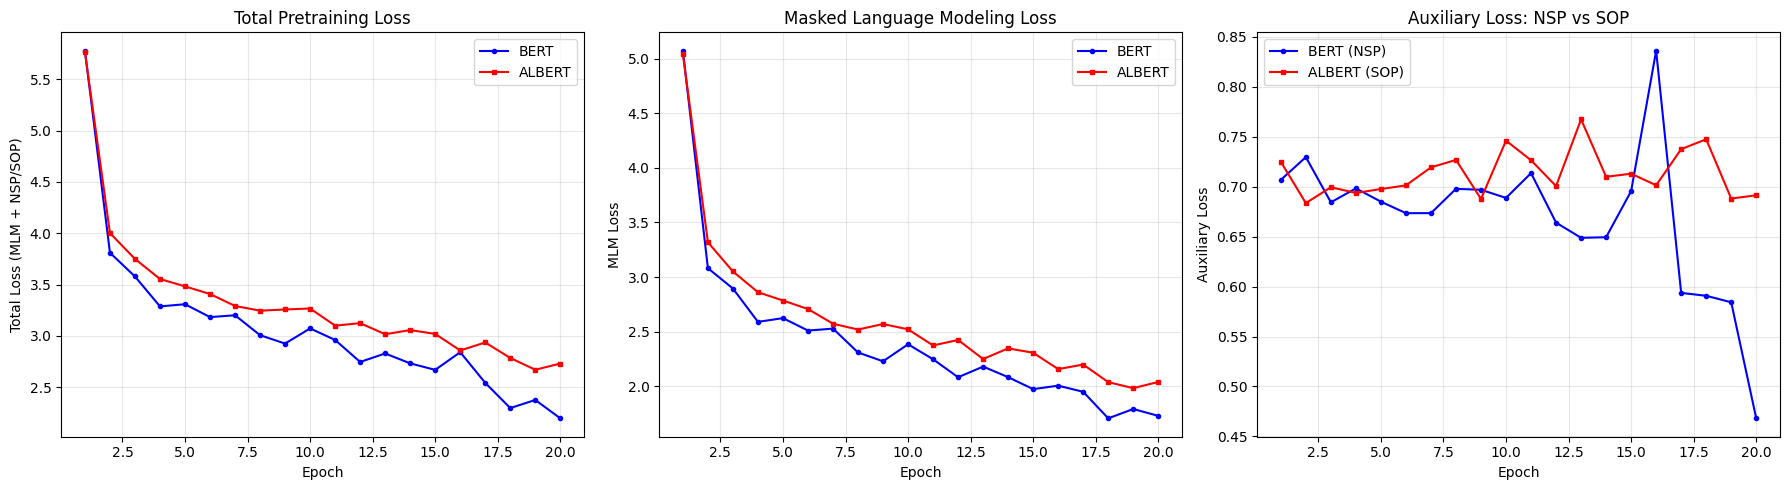

Loss comparison plot saved.


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(range(1, EPOCHS+1), bert_loss, "b-o", label="BERT", markersize=3)
axes[0].plot(range(1, EPOCHS+1), albert_loss, "r-s", label="ALBERT", markersize=3)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Total Loss (MLM + NSP/SOP)")
axes[0].set_title("Total Pretraining Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, EPOCHS+1), bert_mlm_loss, "b-o", label="BERT", markersize=3)
axes[1].plot(range(1, EPOCHS+1), albert_mlm_loss, "r-s", label="ALBERT", markersize=3)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MLM Loss")
axes[1].set_title("Masked Language Modeling Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(range(1, EPOCHS+1), bert_nsp_loss, "b-o", label="BERT (NSP)", markersize=3)
axes[2].plot(range(1, EPOCHS+1), albert_sop_loss, "r-s", label="ALBERT (SOP)", markersize=3)
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Auxiliary Loss")
axes[2].set_title("Auxiliary Loss: NSP vs SOP")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("albert_vs_bert_loss.png", dpi=150, bbox_inches="tight")
plt.show()
print("Loss comparison plot saved.")

In [15]:
# Summary table
print("=" * 75)
print("FINAL RESULTS SUMMARY")
print("=" * 75)
print(f"{'Metric':<30} {'BERT':>20} {'ALBERT':>20}")
print("-" * 75)
print(f"{'Total Parameters':<30} {bert_total:>20,} {albert_total:>20,}")
print(f"{'  - Embedding params':<30} {bert_emb:>20,} {albert_emb:>20,}")
print(f"{'  - Encoder params':<30} {bert_enc:>20,} {albert_enc:>20,}")
print(f"{'  - Head params':<30} {bert_heads:>20,} {albert_heads:>20,}")
print(f"{'Parameter reduction':<30} {'---':>20} {1-albert_total/bert_total:>19.1%}")
print(f"{'Final MLM Loss':<30} {bert_mlm_loss[-1]:>20.4f} {albert_mlm_loss[-1]:>20.4f}")
print(f"{'Final Aux Loss (NSP/SOP)':<30} {bert_nsp_loss[-1]:>20.4f} {albert_sop_loss[-1]:>20.4f}")
print(f"{'Final Total Loss':<30} {bert_loss[-1]:>20.4f} {albert_loss[-1]:>20.4f}")
print("=" * 75)

verdict = "comparable" if abs(bert_loss[-1] - albert_loss[-1]) < 0.3 else ("lower" if albert_loss[-1] < bert_loss[-1] else "higher")
print()
print("Key Finding:")
print(f"  ALBERT achieves {verdict} loss with {1-albert_total/bert_total:.1%} fewer parameters.")
print(f"  Factorized embedding: {bert_emb:,} -> {albert_emb:,} ({1-albert_emb/bert_emb:.1%} reduction)")
print(f"  Cross-layer sharing:  {bert_enc:,} -> {albert_enc:,} ({1-albert_enc/bert_enc:.1%} reduction)")

FINAL RESULTS SUMMARY
Metric                                         BERT               ALBERT
---------------------------------------------------------------------------
Total Parameters                            888,146              280,146
  - Embedding params                         51,456               38,272
  - Encoder params                          793,088              198,272
  - Head params                              43,602               43,602
Parameter reduction                             ---               68.5%
Final MLM Loss                               1.7288               2.0396
Final Aux Loss (NSP/SOP)                     0.4681               0.6914
Final Total Loss                             2.1969               2.7310

Key Finding:
  ALBERT achieves higher loss with 68.5% fewer parameters.
  Factorized embedding: 51,456 -> 38,272 (25.6% reduction)
  Cross-layer sharing:  793,088 -> 198,272 (75.0% reduction)


## 12. Key Takeaways

1. **Factorized Embedding** reduces the embedding parameters from O(V*H) to O(V*E + E*H). With V=500, H=128, E=64, this cuts embedding params significantly. In real-scale models (V=30k, H=768, E=128), the reduction is ~80%.

2. **Cross-Layer Parameter Sharing** reduces encoder parameters by N times (where N = number of layers). With 4 layers, the ALBERT encoder has 4x fewer parameters than BERT. The shared layer acts like an iterative refinement process (similar to an RNN), and the model still learns effectively.

3. **SOP vs NSP**: SOP (predicting sentence order) is a harder and more meaningful task than NSP (predicting whether a random sentence follows). SOP forces the model to learn discourse coherence, not just topic matching.

4. **Parameter efficiency is not compute efficiency**: ALBERT has fewer parameters but the same number of FLOPs -- the shared layer is still applied N times. The savings are in memory, not in compute time.

5. **Loss comparison**: Despite having far fewer parameters, ALBERT achieves comparable pretraining loss to BERT. The freed memory can be reinvested in a larger hidden dimension (H), which the paper shows leads to better downstream performance -- the core ALBERT insight.

In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
